#  Regresión Logistica

**Analítica de datos aplicada a la Ingeniería Civil**

**Caso:** Predecir categorías (hormigón de alta o baja resistencia)

> 🎯 **Mensaje clave:** Hasta ahora hemos predecido un valor numerico de la resistencia. El logisitico nos permite predecir categorías. No modelamos el valor de la resistencia, modelamos la probabilidad de caer en una u otra categoría. 

In [55]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Colores que usaremos en todo el bloque
AZUL = "#4C72B0"      # baja resistencia (clase 0)
NARANJA = "#DD8452"   # alta resistencia (clase 1)
ROJO = "#C44E52"      # modelo
GRIS = "#7F7F7F"      # umbrales

plt.rcParams["font.size"] = 12


def estilo(ax):
    """Estética común de las gráficas: sin bordes arriba y a la derecha, rejilla suave."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(alpha=0.25)

In [56]:
# Si trabajas en local, cambia la ruta por la de tu ordenador
ruta = "/lustre/geocean/WORK/users/alonsoap/personal/dodencia/AnaliticaDeDatos/datos/clases/clase_1_analisis_exploratorio_de_datos/Concrete_Data.xls"
concrete_data = pd.read_excel(ruta, index_col=False)

concrete_data.columns = ["cemento", "escoria", "cenizas", "agua", "superplastificante",
                         "arido_grueso", "arido_fino", "edad", "resistencia"]

variables = ["cemento", "escoria", "cenizas", "agua", "superplastificante",
             "arido_grueso", "arido_fino", "edad"]
X = concrete_data[variables]
y = concrete_data["resistencia"]

X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)   # mismos pliegues para todo el notebook

print("Entrenamiento:", len(X_ent), "mezclas · Prueba:", len(X_pru), "mezclas (no las tocamos)")

Entrenamiento: 824 mezclas · Prueba: 206 mezclas (no las tocamos)


In [57]:
umbral = 40

y_ent
y_ent_log = (y_ent>umbral).astype(int)
y_pru_log = (y_pru>umbral).astype(int)

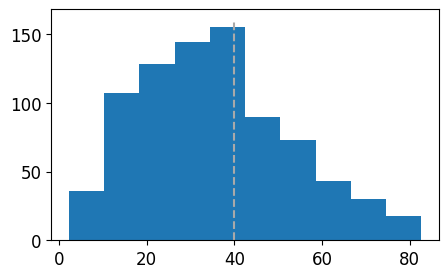

In [58]:
fig, ax = plt.subplots(figsize=(5,3))
ax.hist(y_ent.values)
ax.vlines(umbral,0,160, color = 'darkgray', linestyles='--')
plt.show()

---
## 2. Una sola variable: la curva en S

Empezamos con una variable que ya conocemos, la **relación agua/cemento** (ley de Abrams), para poder dibujarlo todo.

### 2.1. ¿Y si usamos la regresión lineal de siempre?

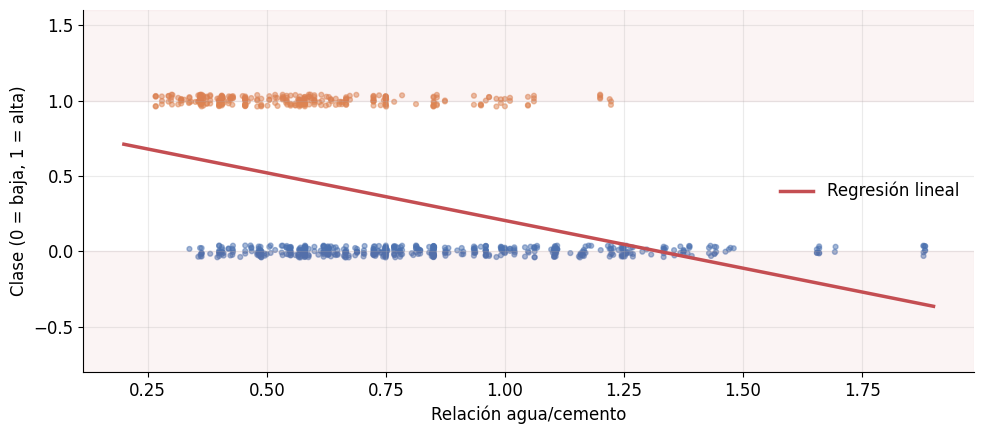

La recta predice 0.71 con a/c = 0,2 y -0.36 con a/c = 1,9


In [59]:
X_ing = X.copy()
X_ing["agua_cemento"] = X["agua"] / X["cemento"]
X_ing["log_edad"] = np.log(X["edad"])
X_ing = X_ing.drop(columns="edad")
X_ing_ent, X_ing_pru = X_ing.loc[X_ent.index], X_ing.loc[X_pru.index]

ac_ent = X_ing_ent[["agua_cemento"]]
rejilla = pd.DataFrame({"agua_cemento": np.linspace(0.2, 1.9, 300)})

recta = LinearRegression().fit(ac_ent, y_ent_log)
pred_recta = recta.predict(rejilla)

rng = np.random.default_rng(0)
salto = rng.uniform(-0.04, 0.04, len(y_ent_log))   # pequeño desplazamiento vertical para ver los puntos

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(ac_ent["agua_cemento"], y_ent_log + salto, c=np.where(y_ent_log == 1, NARANJA, AZUL), s=12, alpha=0.5)
ax.plot(rejilla["agua_cemento"], pred_recta, color=ROJO, linewidth=2.5, label="Regresión lineal")
ax.axhspan(1, 1.6, color=ROJO, alpha=0.06); ax.axhspan(-0.8, 0, color=ROJO, alpha=0.06)
ax.set_ylim(-0.8, 1.6)
ax.set_xlabel("Relación agua/cemento"); ax.set_ylabel("Clase (0 = baja, 1 = alta)")
ax.legend(frameon=False); estilo(ax)
plt.tight_layout(); plt.show()

print(f"La recta predice {pred_recta.max():.2f} con a/c = 0,2 y {pred_recta.min():.2f} con a/c = 1,9")

### 2.2. La regresión logística

La logística calcula la misma combinación lineal de siempre, $z = \beta_0 + \beta_1 x$, y la «dobla» con la función sigmoide para que salga una probabilidad entre 0 y 1:

$$P(\text{alta} \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x)}}$$

La predicción es **alta** si esa probabilidad es mayor que 0,5, es decir, si $z > 0$. La frontera está donde $z = 0$: $\;x^* = -\beta_0 / \beta_1$.

✏️ **Rellena el hueco:** `predict_proba` devuelve una columna por clase; la probabilidad de **alta** es la columna **1**.

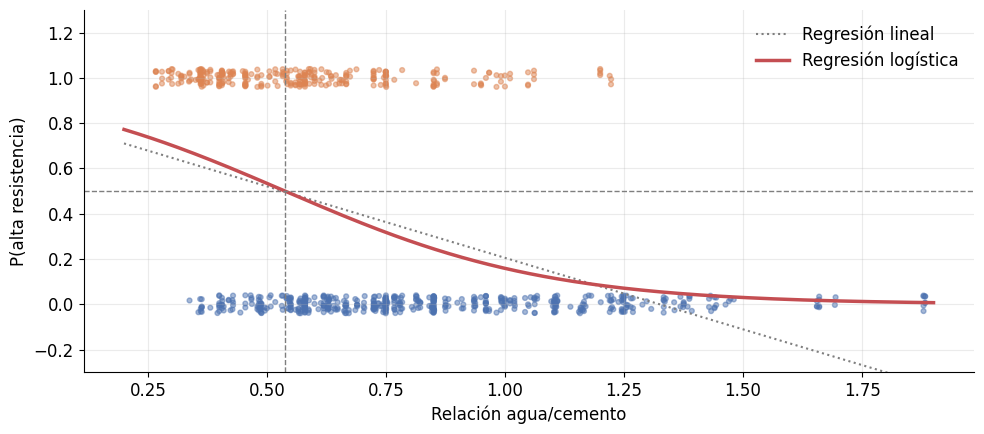

β0 = 1.94 · β1 = -3.61
Frontera: a/c = 0.54 → por debajo predice alta, por encima baja
  a/c = 0.40 → P(alta) = 0.62
  a/c = 0.54 → P(alta) = 0.50
  a/c = 0.80 → P(alta) = 0.28


In [60]:
logistica_ac = LogisticRegression().fit(ac_ent, y_ent_log)
prob_logistica = logistica_ac.predict_proba(rejilla)[:, 1]   # ✏️

b0, b1 = logistica_ac.intercept_[0], logistica_ac.coef_[0, 0]
frontera = -b0 / b1

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(ac_ent["agua_cemento"], y_ent_log + salto, c=np.where(y_ent_log == 1, NARANJA, AZUL), s=12, alpha=0.5)
ax.plot(rejilla["agua_cemento"], pred_recta, color=GRIS, linewidth=1.5, linestyle=":", label="Regresión lineal")
ax.plot(rejilla["agua_cemento"], prob_logistica, color=ROJO, linewidth=2.5, label="Regresión logística")
ax.axhline(0.5, color=GRIS, linestyle="--", linewidth=1)
ax.axvline(frontera, color=GRIS, linestyle="--", linewidth=1)
ax.set_ylim(-0.3, 1.3)
ax.set_xlabel("Relación agua/cemento"); ax.set_ylabel("P(alta resistencia)")
ax.legend(frameon=False); estilo(ax)
plt.tight_layout(); plt.show()

print(f"β0 = {b0:.2f} · β1 = {b1:.2f}")
print(f"Frontera: a/c = {frontera:.2f} → por debajo predice alta, por encima baja")
for ac in [0.4, frontera, 0.8]:
    p = logistica_ac.predict_proba(pd.DataFrame({"agua_cemento": [ac]}))[0, 1]
    print(f"  a/c = {ac:.2f} → P(alta) = {p:.2f}")

---
## 3. Todas las variables: la tabla de clasificadores

Ahora usamos todas las columnas. Como en el Lasso, **escalamos** antes del modelo: la logística de scikit-learn lleva una pequeña penalización por defecto y, sin escalar, dependería de las unidades.

Para clasificar ya no hablamos de MPa de error. Miramos:

- **Exactitud**: porcentaje de mezclas bien clasificadas.
- **Sensibilidad** (*recall*): de las que **son** altas, cuántas detecta el modelo.
- **Precisión**: de las que el modelo **dice** que son altas, cuántas lo son de verdad. Es la que más le importa a la planta: un «alta» equivocado es una mezcla que no llega al C30 y se da por buena.

In [61]:
tabla_modelos = []


def evaluar_clasificador(nombre, modelo, X, y, comentario=""):
    """Validación cruzada de 5 pliegues (siempre los mismos) y una fila nueva en la tabla de modelos."""
    res = cross_validate(modelo, X, y, cv=cv, scoring=["accuracy", "recall", "precision"])
    fila = {"Modelo": nombre,
            "Exactitud": round(res["test_accuracy"].mean(), 3),
            "Sensibilidad": round(res["test_recall"].mean(), 3),
            "Precisión": round(res["test_precision"].mean(), 3),
            "Comentario": comentario}
    tabla_modelos.append(fila)
    return fila


def logistica_escalada():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

In [64]:
evaluar_clasificador("Siempre la clase más frecuente", DummyClassifier(strategy="most_frequent"),
                     X_ent, y_ent_log, "referencia mínima")   # ✏️
evaluar_clasificador("Logística · solo a/c", logistica_escalada(), X_ing_ent[["agua_cemento"]], y_ent_log,
                     "1 variable")
evaluar_clasificador("Logística · 8 variables", logistica_escalada(), X_ent, y_ent_log,
                     "edad en días")
evaluar_clasificador("Logística · a/c + log(edad)", logistica_escalada(), X_ing_ent, y_ent_log,
                     "9 variables con sentido físico")

pd.DataFrame(tabla_modelos)

/nfs/home/geocean/alonsoap/miniforge3/envs/bluemath_tk/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/home/geocean/alonsoap/miniforge3/envs/bluemath_tk/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/home/geocean/alonsoap/miniforge3/envs/bluemath_tk/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(av

,Modelo,Exactitud,Sensibilidad,Precisión,Comentario
0,Siempre la clase más frecuente,NaN,NaN,NaN,referencia mínima
1,Siempre la clase más frecuente,0.636,0.000,0.000,referencia mínima
2,Logística · solo a/c,0.717,0.512,0.640,1 variable
3,Logística · 8 variables,0.808,0.663,0.779,edad en días
4,Logística · a/c + log(edad),0.867,0.779,0.841,9 variables con sentido físico


### 3.1. ¿Se puede leer el modelo?

Con las variables escaladas, cada coeficiente dice cuánto cambia $z$ (el «log-odds») al subir **una desviación típica** esa variable. El signo dice hacia qué clase empuja: positivo hacia **alta**, negativo hacia **baja**.

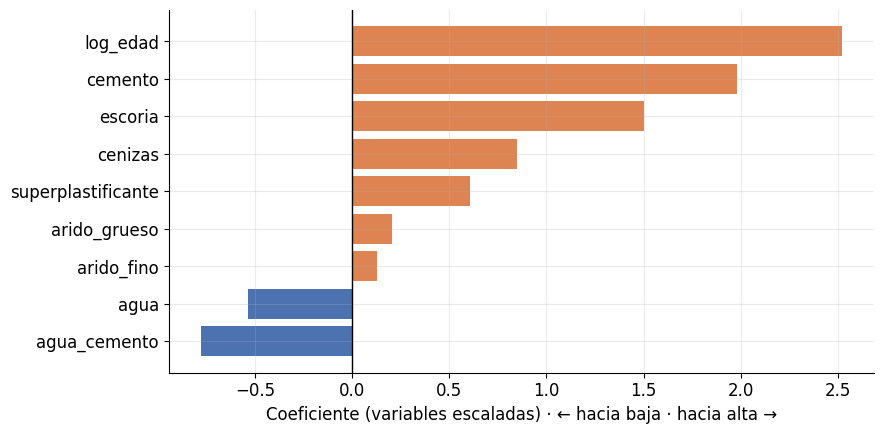

,Coeficiente
cemento,1.98
escoria,1.50
cenizas,0.85
agua,-0.54
superplastificante,0.61
arido_grueso,0.21
arido_fino,0.13
agua_cemento,-0.78
log_edad,2.52


In [66]:
logistica_ing = logistica_escalada().fit(X_ing_ent, y_ent_log)
coef = pd.Series(logistica_ing[-1].coef_[0], index=X_ing.columns)

fig, ax = plt.subplots(figsize=(9, 4.5))
orden = coef.sort_values()
ax.barh(orden.index, orden.values, color=np.where(orden > 0, NARANJA, AZUL))
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Coeficiente (variables escaladas) · ← hacia baja · hacia alta →")
estilo(ax); plt.tight_layout(); plt.show()

coef.round(2).to_frame("Coeficiente")

---
## 4. Sobre el conjunto de prueba: la matriz de confusión

Elegido el modelo (logística con a/c y log(edad)), lo evaluamos **una sola vez** en las mezclas de prueba que no hemos tocado.

|  | Predice baja | Predice alta |
|---|:--:|:--:|
| **Es baja** | ✅ verdadero negativo | ⚠️ **falso positivo**: se acepta una mezcla que no llega |
| **Es alta** | falso negativo: se rechaza una mezcla buena | ✅ verdadero positivo |

✏️ **Rellena el hueco:** las predicciones sobre las mezclas de prueba se obtienen con `predict`.

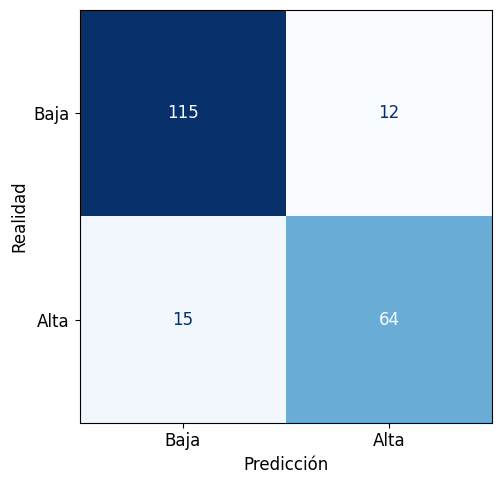

Exactitud en prueba: 86.9%
Falsos positivos (dice alta y es baja): 12 de 76 mezclas aceptadas
Falsos negativos (dice baja y es alta): 15


In [70]:
pred_pru = logistica_ing.predict(X_ing_pru)   # ✏️

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_pru_log, pred_pru), display_labels=["Baja", "Alta"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_xlabel("Predicción"); ax.set_ylabel("Realidad")
plt.tight_layout(); plt.show()

vn, fp, fn, vp = confusion_matrix(y_pru_log, pred_pru).ravel()
print(f"Exactitud en prueba: {accuracy_score(y_pru_log, pred_pru):.1%}")
print(f"Falsos positivos (dice alta y es baja): {fp} de {fp + vp} mezclas aceptadas")
print(f"Falsos negativos (dice baja y es alta): {fn}")